In [1]:
# Download dataset using kagglehub
import kagglehub
path = kagglehub.dataset_download("zom8ie99/maize-seed")
print("Dataset downloaded to:", path)


Dataset downloaded to: /kaggle/input/maize-seed


In [2]:
# List directory to verify structure
!ls -R "$path"

/kaggle/input/maize-seed:
dataset

/kaggle/input/maize-seed/dataset:
dataset  test_set  training_set

/kaggle/input/maize-seed/dataset/dataset:
test_set  training_set

/kaggle/input/maize-seed/dataset/dataset/test_set:
Average  Bad  Excellent  Good  Worst

/kaggle/input/maize-seed/dataset/dataset/test_set/Average:
'Average (100).JPG'  'Average (32).JPG'  'Average (55).JPG'  'Average (78).JPG'
'Average (10).JPG'   'Average (33).JPG'  'Average (56).JPG'  'Average (79).JPG'
'Average (11).JPG'   'Average (34).JPG'  'Average (57).JPG'  'Average (7).JPG'
'Average (12).JPG'   'Average (35).JPG'  'Average (58).JPG'  'Average (80).JPG'
'Average (13).JPG'   'Average (36).JPG'  'Average (59).JPG'  'Average (81).JPG'
'Average (14).JPG'   'Average (37).JPG'  'Average (5).JPG'   'Average (82).JPG'
'Average (15).JPG'   'Average (38).JPG'  'Average (60).JPG'  'Average (83).JPG'
'Average (16).JPG'   'Average (39).JPG'  'Average (61).JPG'  'Average (84).JPG'
'Average (17).JPG'   'Average (3).JPG'	 'Aver

In [3]:
# Setup
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

In [4]:
# Check for GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [6]:
import os

path = kagglehub.dataset_download("zom8ie99/maize-seed")
print("Dataset downloaded to:", path)

# Print the full directory tree to understand structure
for root, dirs, files in os.walk(path):
    print(f"📁 {root}")
    for d in dirs:
        print(f"    📂 {d}")


Dataset downloaded to: /kaggle/input/maize-seed
📁 /kaggle/input/maize-seed
    📂 dataset
📁 /kaggle/input/maize-seed/dataset
    📂 test_set
    📂 dataset
    📂 training_set
📁 /kaggle/input/maize-seed/dataset/test_set
    📂 Good
    📂 Average
    📂 Worst
    📂 Bad
    📂 Excellent
📁 /kaggle/input/maize-seed/dataset/test_set/Good
📁 /kaggle/input/maize-seed/dataset/test_set/Average
📁 /kaggle/input/maize-seed/dataset/test_set/Worst
📁 /kaggle/input/maize-seed/dataset/test_set/Bad
📁 /kaggle/input/maize-seed/dataset/test_set/Excellent
📁 /kaggle/input/maize-seed/dataset/dataset
    📂 test_set
    📂 training_set
📁 /kaggle/input/maize-seed/dataset/dataset/test_set
    📂 Good
    📂 Average
    📂 Worst
    📂 Bad
    📂 Excellent
📁 /kaggle/input/maize-seed/dataset/dataset/test_set/Good
📁 /kaggle/input/maize-seed/dataset/dataset/test_set/Average
📁 /kaggle/input/maize-seed/dataset/dataset/test_set/Worst
📁 /kaggle/input/maize-seed/dataset/dataset/test_set/Bad
📁 /kaggle/input/maize-seed/dataset/dataset/te

## **Data Loading**

In [7]:
import os
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Paths
root_path = "/kaggle/input/maize-seed"
train_dir, test_dir = None, None

# Locate directories
for root, dirs, files in os.walk(root_path):
    for d in dirs:
        if d == "training_set":
            train_dir = os.path.join(root, d)
        elif d == "test_set":
            test_dir = os.path.join(root, d)

# Check
if not train_dir or not test_dir:
    raise FileNotFoundError("training_set or test_set not found.")

# Image size and batch
image_size = (224, 224)
batch_size = 32

# Transforms: similar to ImageDataGenerator
train_transforms = transforms.Compose([
    transforms.Resize(image_size),
    transforms.RandomRotation(20),
    transforms.RandomHorizontalFlip(),
    transforms.RandomAffine(0, translate=(0.2, 0.2), shear=20),
    transforms.RandomResizedCrop(image_size, scale=(0.8, 1.0)),
    transforms.ToTensor(),  # Converts to [0,1] range
])

test_transforms = transforms.Compose([
    transforms.Resize(image_size),
    transforms.ToTensor()
])

# Load datasets
train_dataset = datasets.ImageFolder(root=train_dir, transform=train_transforms)
test_dataset = datasets.ImageFolder(root=test_dir, transform=test_transforms)

# Create loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Print info
print(f"Training dataset: {len(train_dataset)} images, classes: {train_dataset.classes}")
print(f"Test dataset: {len(test_dataset)} images, classes: {test_dataset.classes}")


Training dataset: 2500 images, classes: ['Average', 'Bad', 'Excellent', 'Good', 'Worst']
Test dataset: 500 images, classes: ['Average', 'Bad', 'Excellent', 'Good', 'Worst']


## **Model Building**

In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Initialize model
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.last_channel, len(train_dataset.classes))  # 5 classes
model.to(device)

# Define loss and optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Model, loss, and optimizer initialized.")

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
100%|██████████| 13.6M/13.6M [00:00<00:00, 76.9MB/s]


Model, loss, and optimizer initialized.


## **Model Training**

In [9]:
from tqdm import tqdm

# Training parameters
EPOCHS = 20
train_acc, val_acc = [], []
train_loss_history, val_loss_history = [], []
best_val_acc = 0.0

for epoch in range(EPOCHS):
    # Training
    model.train()
    correct = total = 0
    running_loss = 0.0
    loop = tqdm(train_loader, desc=f"Epoch [{epoch+1}/{EPOCHS}]", leave=False)
    for images, labels in loop:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()
        running_loss += loss.item()
        loop.set_postfix(loss=loss.item())
    train_accuracy = 100 * correct / total
    train_loss = running_loss / len(train_loader)
    train_acc.append(train_accuracy)
    train_loss_history.append(train_loss)
    print(f"Epoch {epoch+1}, Train Loss: {train_loss:.4f}, Train Accuracy: {train_accuracy:.2f}%")

    # Validation
    model.eval()
    correct = total = 0
    val_loss = 0.0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
    val_accuracy = 100 * correct / total
    val_loss = val_loss / len(test_loader)
    val_acc.append(val_accuracy)
    val_loss_history.append(val_loss)
    print(f"Validation Loss: {val_loss:.4f}, Validation Accuracy: {val_accuracy:.2f}%")

    # Save best model
    if val_accuracy > best_val_acc:
        best_val_acc = val_accuracy
        torch.save(model.state_dict(), "best_model.pth")
        print(f"Saved best model with Validation Accuracy: {best_val_acc:.2f}%")
    print("\n")

# Save metrics for plotting
torch.save({
    'train_acc': train_acc,
    'val_acc': val_acc,
    'train_loss': train_loss_history,
    'val_loss': val_loss_history
}, 'training_metrics.pth')

Epoch 1, Train Loss: 0.5916, Train Accuracy: 75.16%
Validation Loss: 0.5433, Validation Accuracy: 76.40%
Saved best model with Validation Accuracy: 76.40%


Epoch 2, Train Loss: 0.2316, Train Accuracy: 91.52%
Validation Loss: 1.1005, Validation Accuracy: 63.00%


Epoch 3, Train Loss: 0.1456, Train Accuracy: 95.00%
Validation Loss: 0.6472, Validation Accuracy: 79.60%
Saved best model with Validation Accuracy: 79.60%


Epoch 4, Train Loss: 0.1533, Train Accuracy: 94.64%
Validation Loss: 0.7794, Validation Accuracy: 78.20%


Epoch 5, Train Loss: 0.1221, Train Accuracy: 95.36%
Validation Loss: 0.4204, Validation Accuracy: 88.20%
Saved best model with Validation Accuracy: 88.20%


Epoch 6, Train Loss: 0.0937, Train Accuracy: 96.72%
Validation Loss: 0.3168, Validation Accuracy: 90.00%
Saved best model with Validation Accuracy: 90.00%


... (10 outputs left out)

Epoch 17, Train Loss: 0.1414, Train Accuracy: 97.28%
Validation Loss: 1.8191, Validation Accuracy: 66.40%


Epoch 18, Train Loss: 0.1594, Train Accuracy: 94.56%
Validation Loss: 0.6270, Validation Accuracy: 78.60%


Epoch 19, Train Loss: 0.0725, Train Accuracy: 97.44%
Validation Loss: 0.6915, Validation Accuracy: 79.00%


Epoch 20, Train Loss: 0.0922, Train Accuracy: 96.88%
Validation Loss: 0.6479, Validation Accuracy: 77.60%


## **Train and Val Curves**

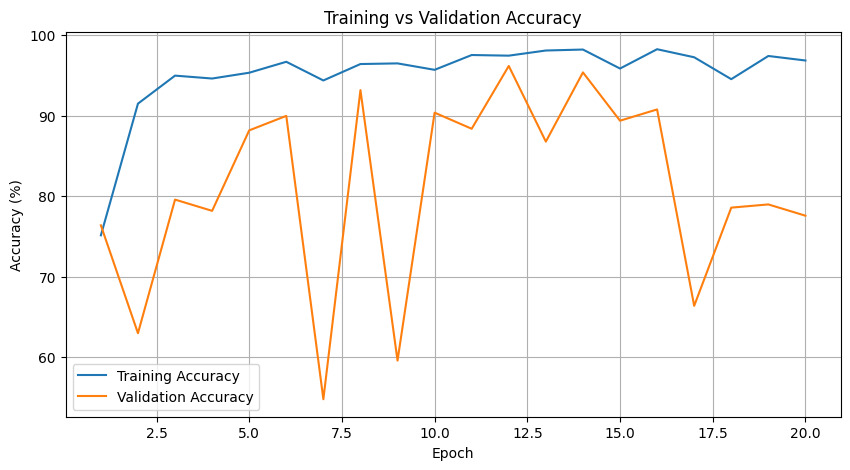

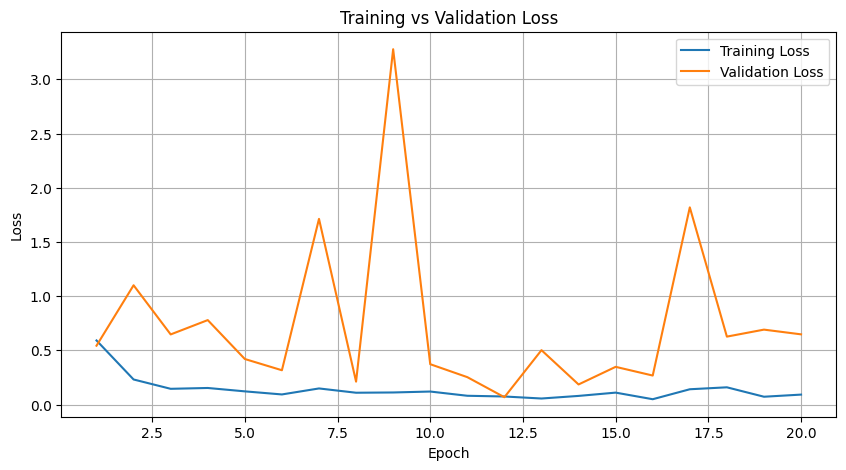

In [10]:
import matplotlib.pyplot as plt

# Load saved metrics
metrics = torch.load('training_metrics.pth')
train_acc = metrics['train_acc']
val_acc = metrics['val_acc']
train_loss = metrics['train_loss']
val_loss = metrics['val_loss']

# Plot Accuracy
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_acc) + 1), train_acc, label='Training Accuracy')
plt.plot(range(1, len(val_acc) + 1), val_acc, label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy (%)')
plt.legend()
plt.grid(True)
# plt.savefig('accuracy_plot.png')
plt.show()

# Plot Loss
plt.figure(figsize=(10, 5))
plt.plot(range(1, len(train_loss) + 1), train_loss, label='Training Loss')
plt.plot(range(1, len(val_loss) + 1), val_loss, label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)
# plt.savefig('loss_plot.png')
plt.show()

## **Correlation Matrix**

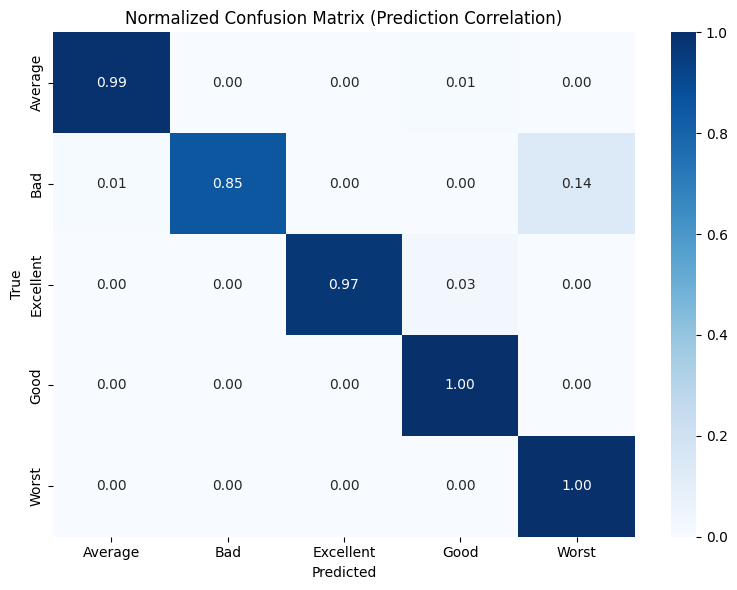

In [11]:
import torch
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from torchvision import models
import torch.nn as nn

# Define device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Rebuild the MobileNetV2 model with correct number of classes
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.last_channel, len(train_dataset.classes))  # e.g., 5 classes
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.to(device)
model.eval()

# Collect predictions and true labels
all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs.data, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# Compute confusion matrix
conf_matrix = confusion_matrix(all_labels, all_preds)

# Normalize confusion matrix row-wise
conf_matrix_norm = conf_matrix / conf_matrix.sum(axis=1, keepdims=True)

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=train_dataset.classes, yticklabels=train_dataset.classes)
plt.title('Normalized Confusion Matrix (Prediction Correlation)')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.tight_layout()
plt.show()


In [12]:
train_dataset.classes

['Average', 'Bad', 'Excellent', 'Good', 'Worst']

## **Sample Prediction**

In [15]:
from google.colab import files
from PIL import Image
import torchvision.transforms as transforms
import torch
import torch.nn as nn
from torchvision import models
import io

# Upload image (opens file explorer)
uploaded = files.upload()

# Load uploaded image directly from memory
image_bytes = next(iter(uploaded.values()))
img = Image.open(io.BytesIO(image_bytes)).convert("RGB")

# Classes
classes = ['Average', 'Bad', 'Excellent', 'Good', 'Worst']

# Show the image
img.show()

# Image transform (same as used during training)
transform = transforms.Compose([
    transforms.Resize((224, 224)),  # MobileNetV2 input size
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])
input_tensor = transform(img).unsqueeze(0)  # Add batch dimension

# Setup device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load trained model
model = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.DEFAULT)
model.classifier[1] = nn.Linear(model.last_channel, len(train_dataset.classes))  # Or set class count manually
model.load_state_dict(torch.load("best_model.pth", map_location=device))
model.to(device)
model.eval()

# Predict
input_tensor = input_tensor.to(device)
with torch.no_grad():
    outputs = model(input_tensor)
    _, predicted = torch.max(outputs, 1)
    predicted_class = classes[predicted.item()]

print(f"🔍 Predicted class: {predicted_class}")


Saving Excellent (12).JPG to Excellent (12) (1).JPG
🔍 Predicted class: Excellent
